In [4]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = "AI dataset.csv.xls"        # (a CSV file, even though it ends with .xls)
SEED = 42                               # fixed random seed -> same results every run

In [5]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (50000, 15)


,state_names,district_names,crop_year,season_names,crop_names,area,temperature,wind_speed,precipitation,humidity,soil_type,N,P,K,production
0,Karnataka,UDUPI,2005,Rabi,Horse-gram,1122.0,20.48349,1.971802,1013.011877,64.876363,silt,10.240,26.624,26.624,836
1,Madhya Pradesh,GWALIOR,2003,Whole Year,Brinjal,194.0,19.95000,1.830000,1013.000000,43.000000,clay,1.288,3.220,1.288,0
2,Andhra Pradesh,CHITTOOR,2010,Rabi,Sesamum,334.0,23.09000,1.410000,1011.000000,91.000000,peaty,0.000,0.000,0.000,118
3,Andhra Pradesh,KRISHNA,2014,Rabi,Tomato,538.0,20.48349,1.971802,1013.011877,64.876363,chalky,2.422,6.055,2.422,7289
4,Uttar Pradesh,SULTANPUR,2011,Rabi,Coriander,59.0,20.48349,1.971802,1013.011877,64.876363,silty,3.610,9.386,9.386,33


In [6]:
steps = [("Raw data", len(df))]

# Step 1: remove extra spaces in text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype(str).str.strip()

# Step 2: production must be a number
df["production"] = pd.to_numeric(df["production"], errors="coerce")
df = df.dropna(subset=["production"])
steps.append(("Removed invalid production values", len(df)))

# Step 3: duplicates
df = df.drop_duplicates()
steps.append(("Removed duplicates", len(df)))

# Step 4: production = 0 or area = 0
df = df[(df["production"] > 0) & (df["area"] > 0)]
steps.append(("Removed production = 0", len(df)))

# Step 5: create the TARGET (yield) and remove the top 0.5 % extreme values
df["yield"] = df["production"] / df["area"]
yield_before = df["yield"].copy()
df = df[df["yield"] <= df["yield"].quantile(0.995)].reset_index(drop=True)
steps.append(("Removed extreme yields (top 0.5 %)", len(df)))

# Yield is very skewed -> we predict log(1 + yield) instead (explained in the EDA below)
df["log_yield"] = np.log1p(df["yield"])

In [7]:
summary = pd.DataFrame(steps, columns=["Step", "Rows left"])
summary["Rows removed"] = (-summary["Rows left"].diff()).fillna(0).astype(int)
display(summary)
print(f"Kept {len(df):,} of {summary['Rows left'][0]:,} rows ({len(df) / summary['Rows left'][0]:.1%}).  Missing values left: {df.isna().sum().sum()}")

,Step,Rows left,Rows removed
0,Raw data,50000,0
1,Removed invalid production values,49246,754
2,Removed duplicates,49246,0
3,Removed production = 0,48524,722
4,Removed extreme yields (top 0.5 %),48281,243


Kept 48,281 of 50,000 rows (96.6%).  Missing values left: 0


In [8]:
for col in ["temperature", "wind_speed", "precipitation", "humidity"]:
    share = df[col].round(4).value_counts(normalize=True).iloc[0]
    print(f"{col:14s}: {share:.0%} of rows have the same value")

temperature   : 94% of rows have the same value
wind_speed    : 94% of rows have the same value
precipitation : 94% of rows have the same value
humidity      : 94% of rows have the same value


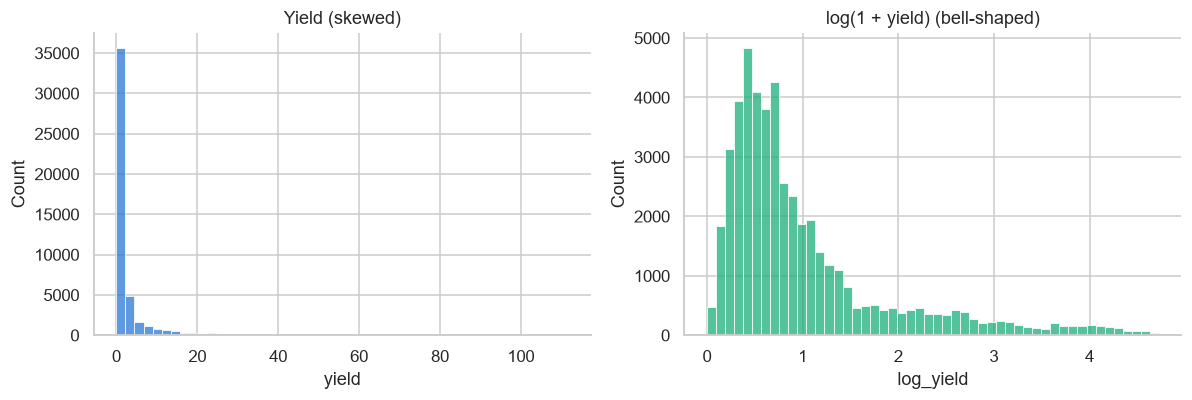

In [9]:
# Why do we use log(yield)?  Raw yield is extremely skewed; the log makes it bell-shaped.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["yield"], bins=50, ax=ax[0], color="#2a78d6");       ax[0].set_title("Yield (skewed)")
sns.histplot(df["log_yield"], bins=50, ax=ax[1], color="#1baf7a");   ax[1].set_title("log(1 + yield) (bell-shaped)")
plt.tight_layout(); plt.show()

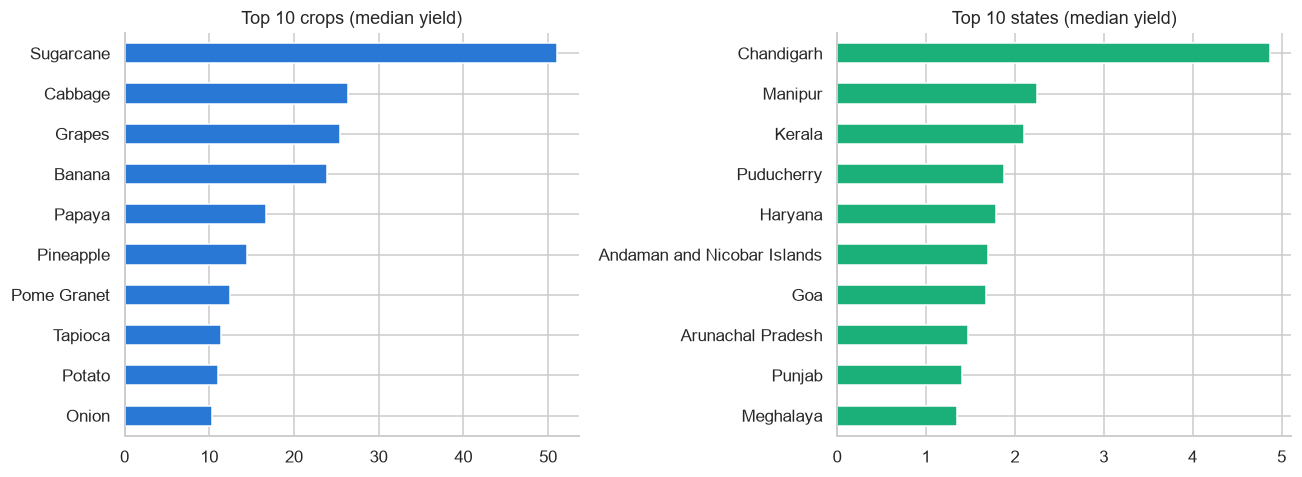

In [10]:
# Which crops and states have the highest yield?
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
df.groupby("crop_names")["yield"].median().nlargest(10)[::-1].plot.barh(ax=ax[0], color="#2a78d6"); ax[0].set_title("Top 10 crops (median yield)")
df.groupby("state_names")["yield"].median().nlargest(10)[::-1].plot.barh(ax=ax[1], color="#1baf7a"); ax[1].set_title("Top 10 states (median yield)")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.show()

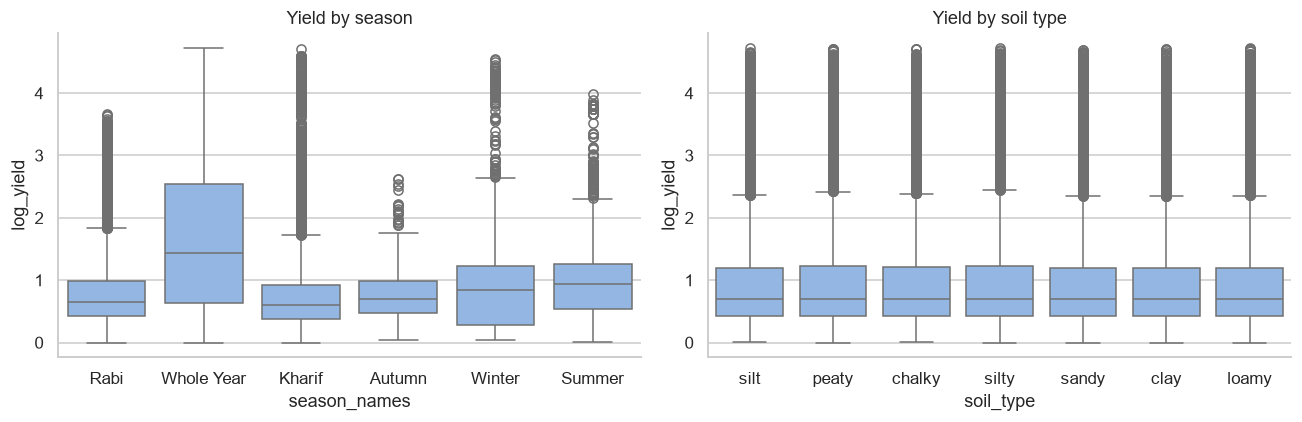

In [11]:
# Does season or soil matter?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="season_names", y="log_yield", ax=ax[0], color="#86b6ef"); ax[0].set_title("Yield by season")
sns.boxplot(data=df, x="soil_type", y="log_yield", ax=ax[1], color="#86b6ef");    ax[1].set_title("Yield by soil type")
plt.tight_layout(); plt.show()

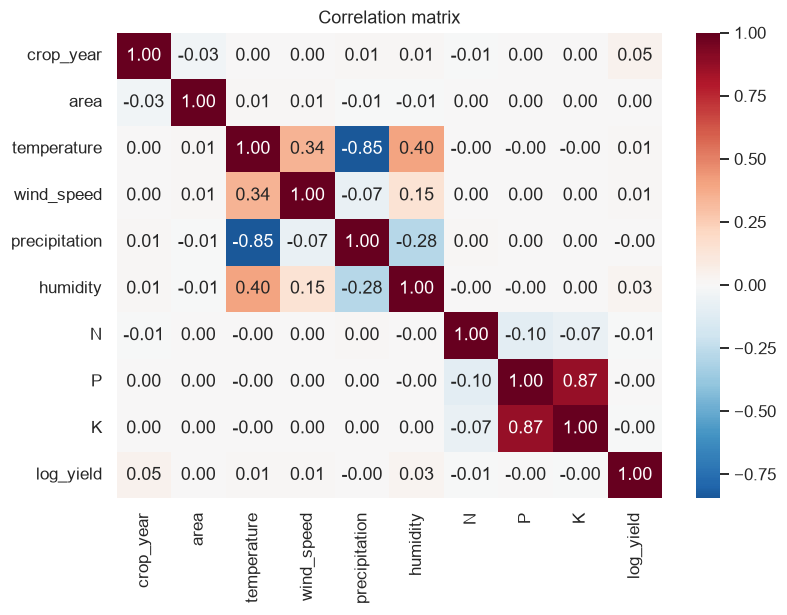

In [12]:
# How are the numeric columns related?
numeric = ["crop_year", "area", "temperature", "wind_speed", "precipitation", "humidity", "N", "P", "K", "log_yield"]
plt.figure(figsize=(8, 5.5))
sns.heatmap(df[numeric].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix"); plt.show()

In [13]:
data = df.copy()
data["log_area"] = np.log1p(data["area"])

numeric_cols = ["crop_year", "log_area", "temperature", "wind_speed", "precipitation", "humidity", "N", "P", "K"]
category_cols = ["crop_names", "state_names", "season_names", "soil_type"]

X = pd.concat([data[numeric_cols], pd.get_dummies(data[category_cols], dtype=float)], axis=1)   # inputs
y = data["log_yield"].values                                                                    # target

print(f"{X.shape[1]} input features = {len(numeric_cols)} numeric + {X.shape[1] - len(numeric_cols)} one-hot columns")
X.head(3)

160 input features = 9 numeric + 151 one-hot columns


,crop_year,log_area,temperature,wind_speed,precipitation,humidity,N,P,K,crop_names_Arcanut (Processed),...,season_names_Summer,season_names_Whole Year,season_names_Winter,soil_type_chalky,soil_type_clay,soil_type_loamy,soil_type_peaty,soil_type_sandy,soil_type_silt,soil_type_silty
0,2005,7.023759,20.48349,1.971802,1013.011877,64.876363,10.240,26.624,26.624,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2010,5.814131,23.09000,1.410000,1011.000000,91.000000,0.000,0.000,0.000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2014,6.289716,20.48349,1.971802,1013.011877,64.876363,2.422,6.055,2.422,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

scaler = StandardScaler().fit(X_train[numeric_cols])

def scale(frame):
    frame = frame.copy()
    frame[numeric_cols] = scaler.transform(frame[numeric_cols])
    return frame.values.astype(float)

Xtr, Xte = scale(X_train), scale(X_test)
print(f"Train: {len(Xtr):,} rows   |   Test: {len(Xte):,} rows   |   Features: {Xtr.shape[1]}")

Train: 38,624 rows   |   Test: 9,657 rows   |   Features: 160


In [15]:
results, test_predictions = {}, {}

def evaluate(name, model, seconds):
    # score one trained model and store the result
    pred_train, pred_test = model.predict(Xtr), model.predict(Xte)
    results[name] = {
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Time (s)": seconds,
    }
    test_predictions[name] = pred_test
    r = results[name]
    print(f"✅ {name:18s} trained in {seconds:5.1f}s  |  train R2 = {r['Train R2']:.3f}  |  test R2 = {r['Test R2']:.3f}  |  test RMSE = {r['Test RMSE']:.3f}")

In [16]:
start = time.time()
linear = LinearRegression().fit(Xtr, y_train)
evaluate("Linear Regression", linear, time.time() - start)

✅ Linear Regression  trained in   0.5s  |  train R2 = 0.841  |  test R2 = 0.824  |  test RMSE = 0.368


In [17]:
class GradientDescentRegressor:
    # Linear regression trained with mini-batch gradient descent

    def __init__(self, lr=0.05, epochs=60, batch_size=256):
        self.lr, self.epochs, self.batch_size = lr, epochs, batch_size

    def fit(self, X, y, verbose=False):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0              # start with all weights = 0
        self.loss_history = []
        rng = np.random.default_rng(SEED)
        for epoch in range(self.epochs):               # one epoch = one pass over the data
            order = rng.permutation(n)
            for start in range(0, n, self.batch_size): # small batches
                idx = order[start:start + self.batch_size]
                error = X[idx] @ self.w + self.b - y[idx]                # prediction - actual
                self.w -= self.lr * 2 * (X[idx].T @ error) / len(idx)    # step against the slope
                self.b -= self.lr * 2 * error.mean()
            self.loss_history.append(np.mean((X @ self.w + self.b - y) ** 2))
            if verbose and (epoch + 1) % 20 == 0:
                print(f"   epoch {epoch + 1:3d}/{self.epochs}   error (MSE) = {self.loss_history[-1]:.4f}")
        return self

    def predict(self, X):
        return X @ self.w + self.b

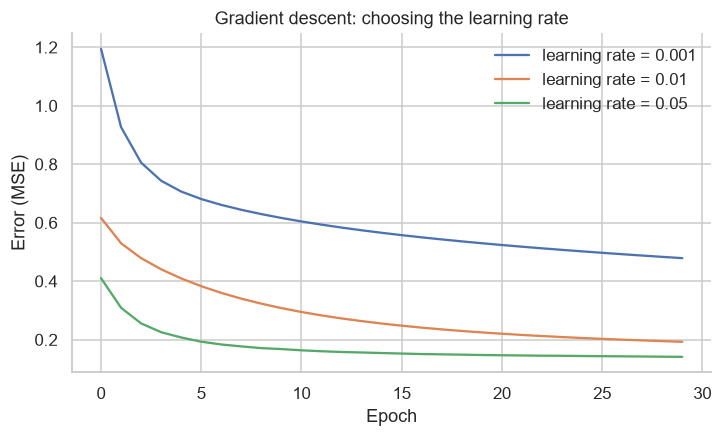

In [18]:
# Effect of the learning rate on how fast the error falls
plt.figure(figsize=(7.5, 4))
for lr in [0.001, 0.01, 0.05]:
    g = GradientDescentRegressor(lr=lr, epochs=30).fit(Xtr, y_train)
    plt.plot(g.loss_history, label=f"learning rate = {lr}")
plt.xlabel("Epoch"); plt.ylabel("Error (MSE)"); plt.title("Gradient descent: choosing the learning rate")
plt.legend(frameon=False); plt.show()

In [19]:
start = time.time()
gradient_descent = GradientDescentRegressor(lr=0.05, epochs=60).fit(Xtr, y_train, verbose=True)
evaluate("Gradient Descent", gradient_descent, time.time() - start)

   epoch  20/60   error (MSE) = 0.1475
   epoch  40/60   error (MSE) = 0.1379
   epoch  60/60   error (MSE) = 0.1341
✅ Gradient Descent   trained in  21.1s  |  train R2 = 0.833  |  test R2 = 0.817  |  test RMSE = 0.376


In [20]:
start = time.time()
search = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                      {"max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 10]}, cv=3, n_jobs=-1)
tree = search.fit(Xtr, y_train).best_estimator_
evaluate("Decision Tree", tree, time.time() - start)
print("   best settings:", search.best_params_)

✅ Decision Tree      trained in  59.7s  |  train R2 = 0.963  |  test R2 = 0.901  |  test RMSE = 0.277
   best settings: {'max_depth': None, 'min_samples_leaf': 5}


In [21]:
start = time.time()
search = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
                      {"max_features": [0.3, 0.5], "min_samples_leaf": [3, 5]}, cv=3)
forest = search.fit(Xtr, y_train).best_estimator_
evaluate("Random Forest", forest, time.time() - start)
print("   best settings:", search.best_params_)

✅ Random Forest      trained in 241.5s  |  train R2 = 0.969  |  test R2 = 0.921  |  test RMSE = 0.247
   best settings: {'max_features': 0.5, 'min_samples_leaf': 3}


In [22]:
start = time.time()
sample = np.random.default_rng(SEED).choice(len(Xtr), size=10000, replace=False)
search = GridSearchCV(SVR(kernel="rbf"), {"C": [1, 10], "epsilon": [0.1, 0.2]}, cv=3, n_jobs=-1)
svm = search.fit(Xtr[sample], y_train[sample]).best_estimator_
evaluate("SVM (SVR)", svm, time.time() - start)
print("   best settings:", search.best_params_)

✅ SVM (SVR)          trained in 114.8s  |  train R2 = 0.886  |  test R2 = 0.846  |  test RMSE = 0.345
   best settings: {'C': 10, 'epsilon': 0.1}


In [23]:
start = time.time()
search = RandomizedSearchCV(XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=-1),
                            {"n_estimators": [300, 500], "learning_rate": [0.05, 0.1],
                             "max_depth": [6, 8, 10], "subsample": [0.8, 1.0], "colsample_bytree": [0.6, 0.8]},
                            n_iter=6, cv=3, random_state=SEED)
xgboost = search.fit(Xtr, y_train).best_estimator_
evaluate("XGBoost", xgboost, time.time() - start)
print("   best settings:", search.best_params_)

✅ XGBoost            trained in 103.0s  |  train R2 = 0.960  |  test R2 = 0.928  |  test RMSE = 0.236
   best settings: {'subsample': 1.0, 'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [24]:
table = pd.DataFrame(results).T
table["Overfit gap"] = table["Train R2"] - table["Test R2"]
table = table.sort_values("Test R2", ascending=False)
best_name = table.index[0]
print(f"{len(table)} / 6 algorithms trained ✅      🏆 Best model: {best_name}\n")
table.round(3)

6 / 6 algorithms trained ✅      🏆 Best model: XGBoost



,Train R2,Test R2,Test RMSE,Test MAE,Time (s),Overfit gap
XGBoost,0.960,0.928,0.236,0.154,102.969,0.032
Random Forest,0.969,0.921,0.247,0.151,241.500,0.048
Decision Tree,0.963,0.901,0.277,0.172,59.716,0.063
SVM (SVR),0.886,0.846,0.345,0.222,114.801,0.040
Linear Regression,0.841,0.824,0.368,0.251,0.528,0.017
Gradient Descent,0.833,0.817,0.376,0.258,21.114,0.017


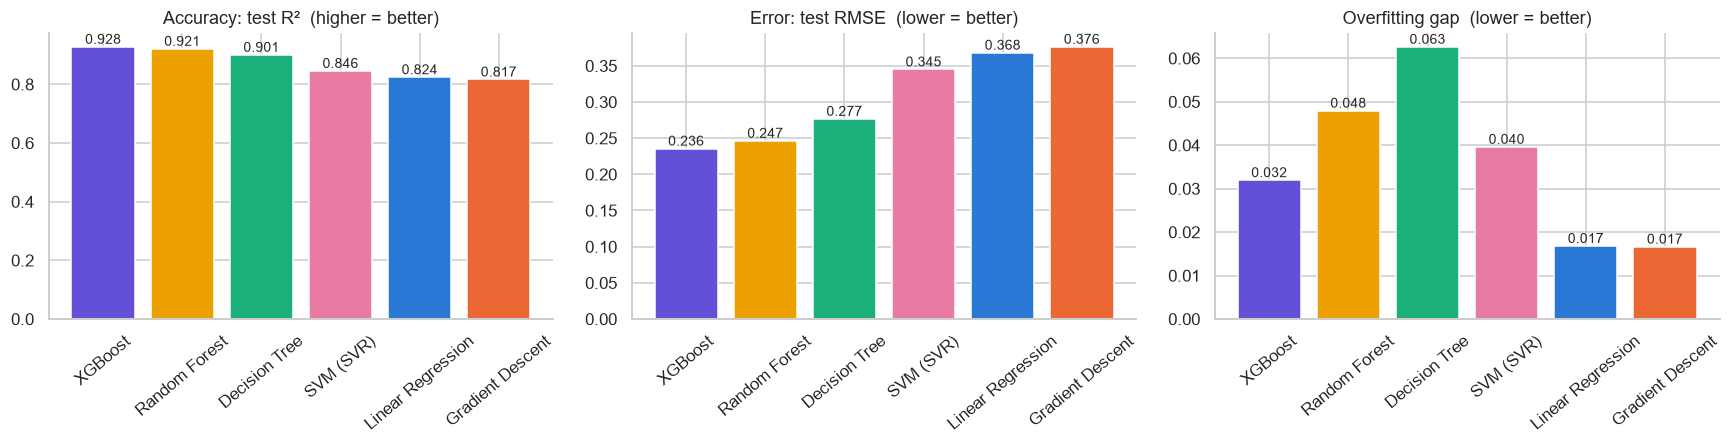

In [25]:
COLORS = {"Linear Regression": "#2a78d6", "Gradient Descent": "#eb6834", "Decision Tree": "#1baf7a",
          "Random Forest": "#eda100", "SVM (SVR)": "#e87ba4", "XGBoost": "#6250d6"}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
panels = [("Test R2", "Accuracy: test R²  (higher = better)"),
          ("Test RMSE", "Error: test RMSE  (lower = better)"),
          ("Overfit gap", "Overfitting gap  (lower = better)")]
for a, (col, title) in zip(ax, panels):
    bars = a.bar(table.index, table[col], color=[COLORS[m] for m in table.index])
    a.set_title(title); a.tick_params(axis="x", rotation=40)
    for b, v in zip(bars, table[col]):
        a.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

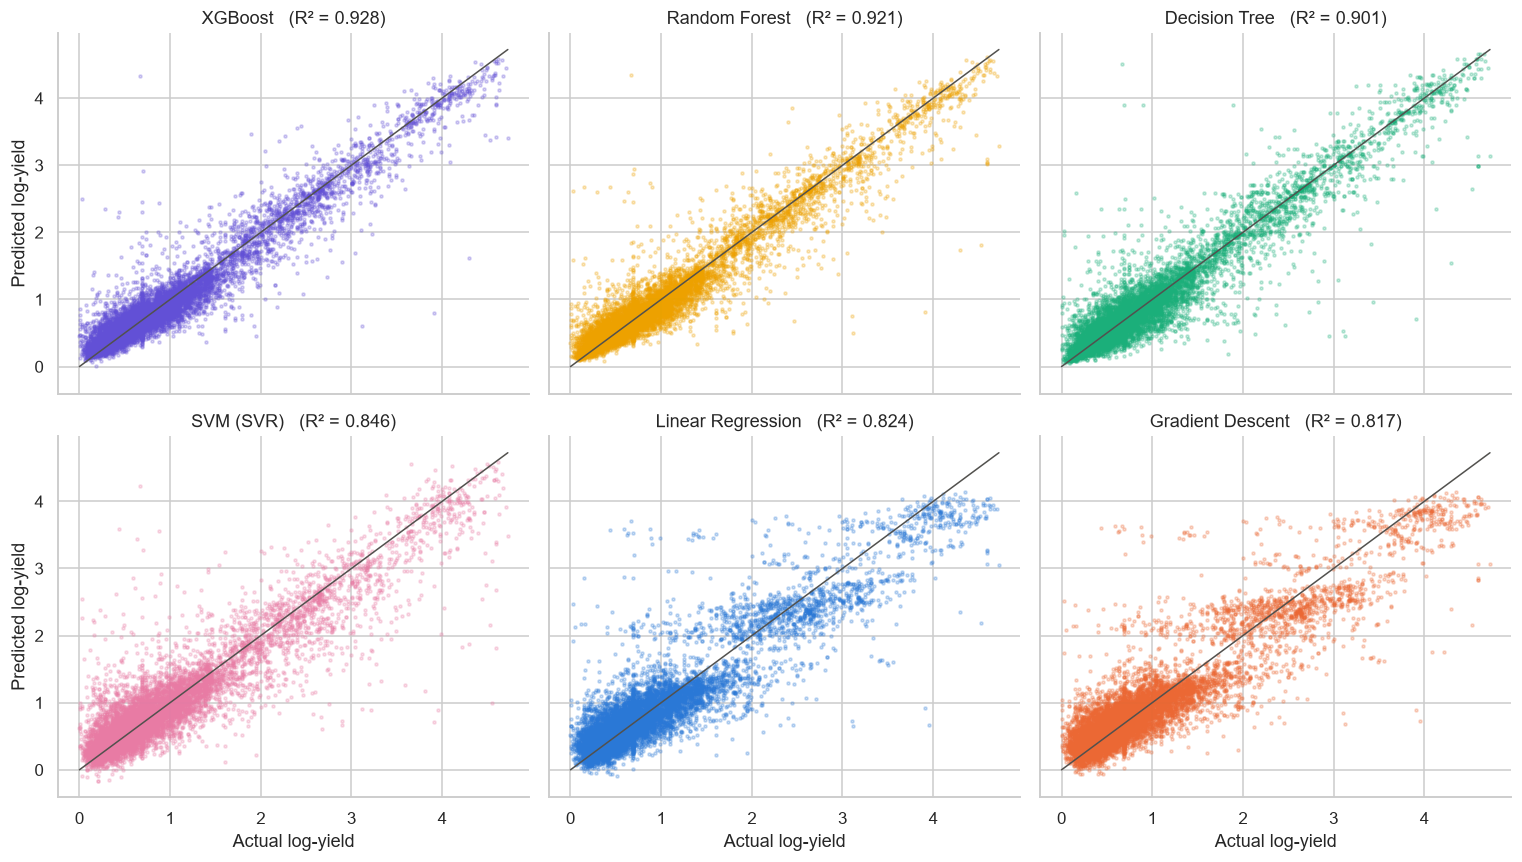

In [26]:
# Actual vs predicted on the test set: points on the diagonal line = perfect prediction
fig, ax = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
line = [y_test.min(), y_test.max()]
for a, name in zip(ax.ravel(), table.index):
    a.scatter(y_test, test_predictions[name], s=4, alpha=0.25, color=COLORS[name])
    a.plot(line, line, color="#52514e", lw=1)
    a.set_title(f"{name}   (R² = {results[name]['Test R2']:.3f})")
for a in ax[1]: a.set_xlabel("Actual log-yield")
for a in ax[:, 0]: a.set_ylabel("Predicted log-yield")
plt.tight_layout(); plt.show()

In [27]:
def predict_yield(model, crop, state, season, soil, area, year=2012, N=50, P=20, K=20):
    row = pd.DataFrame(0.0, index=[0], columns=X.columns)
    weather = [data[c].median() for c in ["temperature", "wind_speed", "precipitation", "humidity"]]   # typical weather
    row.loc[0, numeric_cols] = [year, np.log1p(area), *weather, N, P, K]
    for col in [f"crop_names_{crop}", f"state_names_{state}", f"season_names_{season}", f"soil_type_{soil}"]:
        if col in row.columns:
            row.loc[0, col] = 1.0
    return float(np.expm1(model.predict(scale(row))[0]))        # undo the log

print("Rice,  Punjab,   Kharif, clay, 1000 ha ->", round(predict_yield(xgboost, "Rice", "Punjab", "Kharif", "clay", 1000), 2))
print("Maize, Karnataka, Kharif, silt,  500 ha ->", round(predict_yield(xgboost, "Maize", "Karnataka", "Kharif", "silt", 500), 2))

Rice,  Punjab,   Kharif, clay, 1000 ha -> 2.43
Maize, Karnataka, Kharif, silt,  500 ha -> 2.09


In [28]:
# Rows that have real weather measurements (not the filler value)
filler = data["temperature"].round(4).mode()[0]
real = data[data["temperature"].round(4) != filler].copy()

print(f"Rows with real weather: {len(real):,} of {len(data):,} ({len(real) / len(data):.1%})  |  {real['state_names'].nunique()} states, {real['crop_names'].nunique()} crops")
print(f"'precipitation' in these rows ranges only {real['precipitation'].min():.0f} - {real['precipitation'].max():.0f}  -> rainfall cannot be analysed")
real[["temperature", "humidity", "wind_speed"]].describe().loc[["mean", "min", "max"]].round(2)

Rows with real weather: 2,798 of 48,281 (5.8%)  |  4 states, 73 crops
'precipitation' in these rows ranges only 1009 - 1023  -> rainfall cannot be analysed


,temperature,humidity,wind_speed
mean,20.34,64.97,1.93
min,2.43,37.00,0.27
max,25.94,96.00,3.49


In [29]:
# Regression:  log_yield = climate effects + crop + state + season + year trend
climate_vars = ["temperature", "humidity", "wind_speed"]
controls = pd.concat([pd.get_dummies(real[["crop_names", "state_names", "season_names"]], drop_first=True, dtype=float),
                      real[["crop_year"]] - 2000], axis=1)
Z = np.column_stack([np.ones(len(real)), real[climate_vars].values, controls.values])
t = real["log_yield"].values

beta = np.linalg.lstsq(Z, t, rcond=None)[0]                  # fitted coefficients
resid = t - Z @ beta
inv = np.linalg.pinv(Z.T @ Z)                                # robust (HC1) standard errors
cov = inv @ ((Z * resid[:, None] ** 2).T @ Z) @ inv * len(t) / (len(t) - np.linalg.matrix_rank(Z))
se = np.sqrt(np.diag(cov))

pick = [1, 2, 3]                                             # positions of the 3 climate variables
pct = lambda c: 100 * (np.exp(c) - 1)                        # coefficient -> % change in yield
effects = pd.DataFrame({
    "Effect on yield (%)": pct(beta[pick]),
    "95% range low": pct(beta[pick] - 1.96 * se[pick]),
    "95% range high": pct(beta[pick] + 1.96 * se[pick]),
    "Clear effect?": np.where(np.abs(beta[pick] / se[pick]) > 1.96, "Yes", "No (range includes 0)"),
}, index=["Temperature (+1 °C)", "Humidity (+1 %-point)", "Wind speed (+1 unit)"])
effects.round(2)

,Effect on yield (%),95% range low,95% range high,Clear effect?
Temperature (+1 °C),-0.18,-0.68,0.32,No (range includes 0)
Humidity (+1 %-point),0.52,0.26,0.77,Yes
Wind speed (+1 unit),4.65,2.97,6.36,Yes


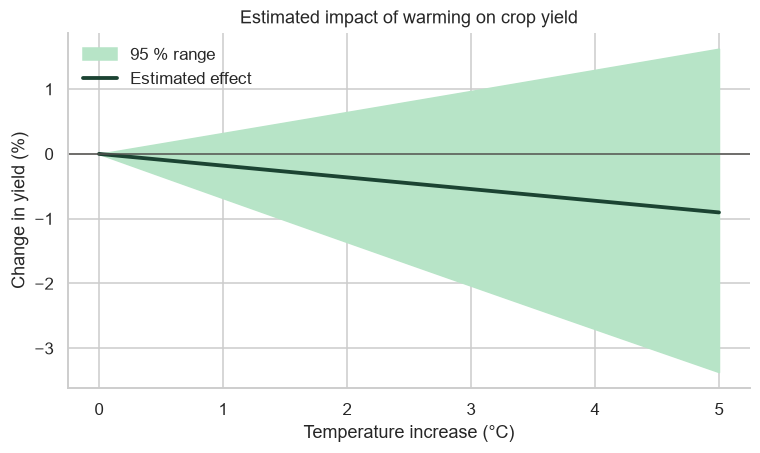

In [30]:
# What does warming do to yield?  (effect with its 95 % uncertainty band)
warming = np.linspace(0, 5, 51)
est = pct(beta[1] * warming)
low = pct((beta[1] - 1.96 * se[1]) * warming)
high = pct((beta[1] + 1.96 * se[1]) * warming)

plt.figure(figsize=(8, 4.2))
plt.fill_between(warming, low, high, color="#b7e4c7", label="95 % range")
plt.plot(warming, est, color="#1b4332", lw=2.5, label="Estimated effect")
plt.axhline(0, color="#52514e", lw=1)
plt.xlabel("Temperature increase (°C)"); plt.ylabel("Change in yield (%)")
plt.title("Estimated impact of warming on crop yield"); plt.legend(frameon=False); plt.show()

In [31]:
%%writefile portable_model.py
"""
portable_model.py  -  save & load trained models WITHOUT version problems.

Why this file exists
--------------------
Pickling a scikit-learn / XGBoost object only works on the SAME library version
(otherwise: "XGBoostError: input stream corrupted"). So instead we convert every
model into plain numbers (tree structure, weights, support vectors) and write our
own tiny predict function. Result: the Streamlit app needs only numpy.

Used by:  the notebook (to_portable, portable_predict)   and   app.py (portable_predict)
"""
import json
import numpy as np


# ------------------------------------------------------------------ 1. convert a trained model
def _sklearn_tree(est):
    t = est.tree_
    return {"left": t.children_left.astype(np.int32), "right": t.children_right.astype(np.int32),
            "feature": t.feature.astype(np.int32), "threshold": t.threshold.astype(np.float64),
            "value": t.value[:, 0, 0].astype(np.float64), "strict": False}   # rule: x <= threshold -> go left


def _xgboost_trees(model):
    # Read the trees from XGBoost's own JSON dump (exact numbers, works on all XGBoost versions)
    dump = json.loads(model.get_booster().save_raw("json"))
    trees = []
    for t in dump["learner"]["gradient_booster"]["model"]["trees"]:
        left = np.array(t["left_children"], dtype=np.int32)
        trees.append({"left": left, "right": np.array(t["right_children"], dtype=np.int32),
                      "feature": np.array(t["split_indices"], dtype=np.int32),
                      "threshold": np.array(t["split_conditions"], dtype=np.float32),   # for leaves this holds the leaf value
                      "value": np.array(t["split_conditions"], dtype=np.float64),
                      "strict": True})                                                  # rule: x < threshold -> go left
    base = dump["learner"]["learner_model_param"]["base_score"]
    return trees, float(str(base).strip("[]"))


def to_portable(model):
    """Turn a trained model into plain numpy arrays / numbers."""
    kind = type(model).__name__
    if kind in ("LinearRegression",):
        return {"type": "linear", "w": model.coef_.astype(np.float64), "b": float(model.intercept_)}
    if kind == "GradientDescentRegressor":                           # our own class from the notebook
        return {"type": "linear", "w": np.asarray(model.w, dtype=np.float64), "b": float(model.b)}
    if kind == "DecisionTreeRegressor":
        return {"type": "tree", **_sklearn_tree(model)}
    if kind == "RandomForestRegressor":
        return {"type": "forest", "trees": [_sklearn_tree(e) for e in model.estimators_]}
    if kind == "SVR":
        return {"type": "svr", "sv": model.support_vectors_.astype(np.float64),
                "dual_coef": model.dual_coef_[0].astype(np.float64),
                "b": float(model.intercept_[0]), "gamma": float(model._gamma)}
    if kind == "XGBRegressor":
        trees, base = _xgboost_trees(model)
        return {"type": "xgb", "trees": trees, "base": base}
    raise ValueError(f"Unknown model type: {kind}")


# ------------------------------------------------------------------ 2. predict with the portable form
def _predict_tree(t, X32):
    node = np.zeros(len(X32), dtype=np.int64)          # every row starts at the root
    rows = np.arange(len(X32))
    while True:
        is_leaf = t["left"][node] == -1
        if is_leaf.all():
            return t["value"][node]
        x = X32[rows, np.where(is_leaf, 0, t["feature"][node])]
        go_left = (x < t["threshold"][node]) if t["strict"] else (x <= t["threshold"][node])
        node = np.where(is_leaf, node, np.where(go_left, t["left"][node], t["right"][node]))


def portable_predict(m, X):
    """Predict log(1 + yield) for an (n_rows, n_features) matrix."""
    X = np.asarray(X, dtype=np.float64)
    kind = m["type"]
    if kind == "linear":                                # Linear Regression / Gradient Descent
        return X @ m["w"] + m["b"]
    X32 = X.astype(np.float32)                          # tree libraries compare in float32
    if kind == "tree":                                  # Decision Tree
        return _predict_tree(m, X32)
    if kind == "forest":                                # Random Forest = average of trees
        return np.mean([_predict_tree(t, X32) for t in m["trees"]], axis=0)
    if kind == "xgb":                                   # XGBoost = base + sum of trees
        return m["base"] + np.sum([_predict_tree(t, X32) for t in m["trees"]], axis=0)
    if kind == "svr":                                   # RBF-kernel SVR
        sq_dist = (X ** 2).sum(1)[:, None] + (m["sv"] ** 2).sum(1)[None, :] - 2 * X @ m["sv"].T
        return np.exp(-m["gamma"] * sq_dist) @ m["dual_coef"] + m["b"]
    raise ValueError(f"Unknown model type: {kind}")


Overwriting portable_model.py


In [32]:
import os, traceback, joblib
from portable_model import to_portable, portable_predict

trained = {"Linear Regression": linear, "Gradient Descent": gradient_descent, "Decision Tree": tree,
           "Random Forest": forest, "SVM (SVR)": svm, "XGBoost": xgboost}

portable = {}
for name, model in trained.items():
    try:
        portable[name] = to_portable(model)
        # check: the saved copy must predict exactly like the original model
        diff = np.abs(model.predict(Xte[:500]) - portable_predict(portable[name], Xte[:500])).max()
        print(f"{'✔' if diff < 1e-3 else '⚠'} {name:18s} saved copy vs original: max difference {diff:.1e}")
    except Exception:
        print(f"❌ {name} could NOT be converted (it is skipped, the others are still saved):")
        traceback.print_exc(limit=2)

✔ Linear Regression  saved copy vs original: max difference 0.0e+00
✔ Gradient Descent   saved copy vs original: max difference 0.0e+00
✔ Decision Tree      saved copy vs original: max difference 0.0e+00
✔ Random Forest      saved copy vs original: max difference 1.8e-15
✔ SVM (SVR)          saved copy vs original: max difference 1.2e-12
✔ XGBoost            saved copy vs original: max difference 4.6e-06


In [34]:
import copy
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_percentage_error

# the models you already trained above
all_models = {"Linear Regression": linear, "Gradient Descent": gradient_descent, "Decision Tree": tree,
              "Random Forest": forest, "SVM (SVR)": svm, "XGBoost": xgboost}

def cross_val_r2(model, X, y, folds=3, max_rows=10000):
    # K-fold cross-validation on a 10,000-row sample of the training data (keeps it fast)
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), size=min(max_rows, len(X)), replace=False)
    scores = []
    for train_part, val_part in KFold(folds, shuffle=True, random_state=SEED).split(idx):
        clone = copy.deepcopy(model).fit(X[idx[train_part]], y[idx[train_part]])
        scores.append(r2_score(y[idx[val_part]], clone.predict(X[idx[val_part]])))
    return float(np.mean(scores))

# MAPE is measured in real yield units (undo the log); yields below 0.1 are skipped because % error explodes near zero
actual = np.expm1(y_test)
keep = actual >= 0.1

for name, model in all_models.items():
    predicted = np.expm1(np.clip(test_predictions[name], 0, None))
    results[name]["MAPE"] = mean_absolute_percentage_error(actual[keep], predicted[keep])
    results[name]["CV R2"] = cross_val_r2(model, Xtr, y_train)
    print(f"✔ {name:18s} CV R2 = {results[name]['CV R2']:.3f}   MAPE = {results[name]['MAPE']:.1%}")

✔ Linear Regression  CV R2 = 0.832   MAPE = 66.7%
✔ Gradient Descent   CV R2 = 0.789   MAPE = 68.0%
✔ Decision Tree      CV R2 = 0.809   MAPE = 41.1%
✔ Random Forest      CV R2 = 0.858   MAPE = 36.9%
✔ SVM (SVR)          CV R2 = 0.832   MAPE = 59.5%
✔ XGBoost            CV R2 = 0.899   MAPE = 37.4%
